In [490]:
# Red neuronal hardwired, para aprender los distintos pasos del aprendizaje
# La red consiste en una capa de entrada de dos neuronas, 
# una capa oculta de tres neuronas con función de activación sigmoidea o ReLU 
# y una capa de salida con función sigmoidea.


In [491]:
%config InlineBackend.figure_format = 'retina'
import matplotlib.pyplot as plt
import numpy as np
import copy
import random

In [492]:
# Crea un array de números aletorios con distribución normal de media cero y desviación estándar 1
def random_init(longitud):
    return (np.random.randn(longitud))

# Crea los datos de entrada. 
def crea_datos(numpuntos):
    inputs = [np.array(np.random.rand(numpuntos))]  # Fila 0, valores x
    inputs.append(np.random.rand(numpuntos))        # Fila 1, valores y   
    inputs.append(np.zeros(numpuntos))              # Fila 2, etiquetas
    for i in range(numpuntos):
        inputs[2][i] = ((inputs[1][i]**2+inputs[0][i]**2)<0.5) #or (inputs[0][i]>0.9)
        #inputs[2][i] = ((inputs[1][i]+inputs[0][i])<1)
    return inputs

In [493]:
def plot_data(data,plabels=""):
    fig = plt.figure(figsize=(5,5))
    ax = fig.add_subplot(111)
    cols=["blue","green","red"]
    for v in range(3):
        dplot = data[data[:,2]==v]
        if len(plabels)==0:
            pass 
        else:
            dplot = data[plabels==v]
        ax.scatter(dplot[:,0], dplot[:,1], color=cols[v], s=10,  zorder=50)
    nudge = 0.02
    ax.set_aspect('equal', 'datalim')
    plt.show()
    return

In [494]:
NUM_PUNTOS_ALL = 10000
NUM_PUNTOS_TRAIN = round(0.8*NUM_PUNTOS_ALL)
NUM_PUNTOS_TEST = NUM_PUNTOS_ALL - NUM_PUNTOS_TRAIN

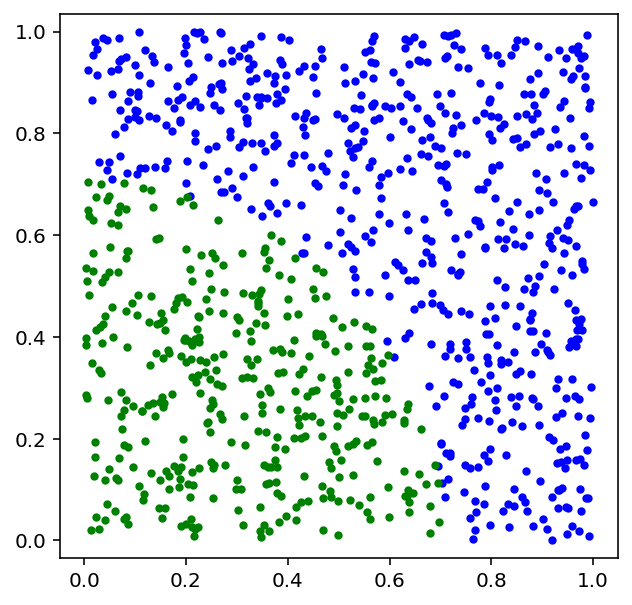

In [495]:
train_samples = crea_datos(NUM_PUNTOS_TRAIN)
datos=[[train_samples[0][i],train_samples[1][i],train_samples[2][i]] for i in range(NUM_PUNTOS_TRAIN)]
datos=np.array(datos).reshape(NUM_PUNTOS_TRAIN,3)
labels=np.array(train_samples[2:])
numpuntosplot=1000
plot_data(datos[0:numpuntosplot])
test_samples = crea_datos(NUM_PUNTOS_TEST)

La red consiste en una capa de entrada de dos neuronas, una capa oculta de tres neuronas con función de activación sigmoidea o ReLU y una capa de salida con función sigmoidea.

In [496]:
# Función para crear un tensor para almacenar valores de las activaciones, errores, etc...
def create_void_cols(dim):
    vcol = list()
    for i in dim:
        vcol.append( np.zeros(i,dtype=np.float64))
    return(vcol)

In [497]:
cost_train=np.zeros(NUM_PUNTOS_TRAIN)
learning_rate = 0.1                       # Tasa de aprendizaje
a = create_void_cols([2,3,1])             # Tensor de activaciones
z=copy.deepcopy(a)                        # Tensor de sumas ponderadas
z[0][0]= -1                               # El elemento 0 se inicializa a -1 porque no tiene sentido
z[0][1]= -1
d=copy.deepcopy(a)

In [498]:
w = [np.array([0,0])]
w.append(np.array(random_init(6)).reshape(2,3))
w.append(np.array(random_init(3)).reshape(3,1)) # Matrices de pesos
b = [np.array([0,0])]
b.append(np.zeros(3))                          
b.append(np.zeros(1))                          # Sesgos, inicializados a 0
delta_l = create_void_cols([1,3,1])            # Errores de cada neurona, para la retropropagación
nabla_w = copy.deepcopy(w)                     # Gradientes de los pesos
nabla_b = [np.zeros(bs.shape) for bs in b]     # Gradientes de los sesgos

In [499]:
# Funciones de activación
def sigmoid(z):
    return(1.0 / (1+np.exp(-1*z)))

def ReLU(z):
    mdatos = copy.deepcopy(z)
    for i in np.arange(len(mdatos)):
        if mdatos[i]<0:
            mdatos[i] = 0
    return(mdatos)

# Procesamiento en una capa en la propagación hacia adelante: activación(suma ponderada) 
def NN_procesar(mya,myb,w,function="sigmoid"):
    mz = np.dot(w.transpose(),mya)+myb
    if (function=="sigmoid"):
        return(mz,sigmoid(mz))
    if (function=="ReLU"):
        return(mz,ReLU(mz))

In [500]:
# Propagación en la red neuronal multicapa
def forward_prop(inp,b,w):
    global a,z
    z[1],a[1] = NN_procesar(inp,b[1],w[1],"ReLU")
    z[2],a[2] = NN_procesar(a[1],b[2],w[2],"sigmoid")
    return(z,a)

In [501]:
def evaluar_clasificacion(samples,num_puntos_sample):
    global a
    aciertos = 0
    predicciones = []
    for i in range(num_puntos_sample):
        a[0][0] = samples[0][i]
        a[0][1] = samples[1][i]
        z,a = forward_prop(a[0],b,w)
        pred = float(z[-1][0]>0.5)
        predicciones.append(pred)
        aciertos += pred == samples[2][i]
    return(aciertos,predicciones)

In [502]:
# Evaluación del error de clasificación con los pesos aleatorios sobre el conjunto de entrenamiento
# Se usa solo como base para comparar
aciertos,predicciones = evaluar_clasificacion(train_samples, NUM_PUNTOS_TRAIN)
tasa_antes=(aciertos/NUM_PUNTOS_TRAIN)

In [503]:
tasa_antes

0.604

In [504]:
### Fórmulas de backprop
# d^L = Grad_a C . s'(z^L)
# d^l = ((w^l+1)T . s'(z^l)
# Grad_bj C = d_j^l
# Grad_w_jk^l = a_k^(l-1) d_j^l

# Derivadas de las funciones de activación
def sigmoid_derivada(z):
    return(sigmoid(z)*(1-sigmoid(z)))

def ReLU_derivada(z):
    mdatos = copy.deepcopy(z)
    for i in np.arange(len(mdatos)):
        if mdatos[i]>0:
            mdatos[i] = 1
        else:
            mdatos[i]=0
    return(mdatos)

# Derivada de la función de coste
def cost_derivada (salidas,y):
    return (salidas-y)

# Retropropagación
def backprop(a,y,z, delta_l, b, w, nw,nb):
    # backward pass
    d_nabla_b, d_nabla_w = nb, nw
    cost = (1/2)*(a[-2]-y)**2
    delta_L = cost_derivada(z[-1],y) * sigmoid_derivada(z[-1]) 
    delta_l[-1] = delta_L
    d_nabla_b[-1] = delta_L
    d_nabla_w[-1] = delta_L*a[-2].reshape(3,1)
    delta_l[-2] = np.dot(w[-1],delta_l[-1])*ReLU_derivada(z[-2])
    d_nabla_b[-2] = delta_l[-2]
    d_nabla_w[-2] = np.array([(a[-3].reshape(1,2).T)*delta_l[-2]]).reshape(2,3)
    return d_nabla_w,d_nabla_b,cost[0]

In [505]:
# SGD
batch_length = 10
numepocas=200
indices = list(range(NUM_PUNTOS_TRAIN))
for ne in range(numepocas):
    random.shuffle(indices)
    for d in range(3):
        train_samples[d][:] = [train_samples[d][i] for i in indices]
    
    nabla_b = [np.zeros(mb.shape ) for mb in b ]
    nabla_w = [np.zeros(mw.shape ) for mw in w ]
    epoch_cost = 0
    nbatches = round(NUM_PUNTOS_TRAIN/batch_length)
    for binepoch in range(nbatches):
        d_nabla_b = [np.zeros(mb.shape ) for mb in b ]
        d_nabla_w = [np.zeros(mw.shape ) for mw in w ]
        for bsample in range(batch_length):
            k = binepoch*batch_length + bsample
            a[0][0] = train_samples[0][k]
            a[0][1] = train_samples[1][k]
            label=train_samples[2][k]
            z,a = forward_prop(a[0],b,w)
            dd_nabla_w,dd_nabla_b,mycost = backprop(a,label,z, delta_l, b, w, nabla_w, nabla_b)
            d_nabla_b += dd_nabla_b
            d_nabla_w += dd_nabla_w
            epoch_cost+=mycost
        nabla_b = [nb+dnb for nb , dnb in zip(nabla_b , d_nabla_b )]
        nabla_w = [nw+dnw for nw , dnw in zip(nabla_w , d_nabla_w )]
        w=[weight-(learning_rate/batch_length)*nabla for weight,nabla in zip(w,nabla_w)]
        b=[bias-(learning_rate/batch_length)*nabla for bias,nabla in zip(b,nabla_b)]
    if (ne%10==0):    
        print(f"Epoca {ne}, Cost {epoch_cost/batch_length:.04f}")
    

Epoca 0, Cost 148.0936
Epoca 10, Cost 157.7881
Epoca 20, Cost 158.4023
Epoca 30, Cost 158.4002
Epoca 40, Cost 158.4001
Epoca 50, Cost 158.4000
Epoca 60, Cost 158.4000
Epoca 70, Cost 158.4000
Epoca 80, Cost 158.4000
Epoca 90, Cost 158.4000
Epoca 100, Cost 158.4000
Epoca 110, Cost 158.4000
Epoca 120, Cost 158.4000
Epoca 130, Cost 158.4000
Epoca 140, Cost 158.4000
Epoca 150, Cost 158.4000
Epoca 160, Cost 158.4000
Epoca 170, Cost 158.4000
Epoca 180, Cost 158.4000
Epoca 190, Cost 158.4000


In [506]:
aciertos, predicciones = evaluar_clasificacion(test_samples, NUM_PUNTOS_TEST)
tasa_test=(aciertos/NUM_PUNTOS_TEST)

In [507]:
print(aciertos)

1863


In [508]:
print("tasa de acierto en test",tasa_test)

tasa de acierto en test 0.9315


In [509]:
numpuntosplot = min(1000,NUM_PUNTOS_TEST)
datos=[[test_samples[0][i],test_samples[1][i],test_samples[2][i]] for i in range(numpuntosplot)]
datos=np.array(datos).reshape(numpuntosplot,3)
labels=np.array(predicciones)[0:numpuntosplot]
fallos = 0
for i in range(numpuntosplot):
    if (labels[i] != test_samples[2][i]):
        fallos +=1
        labels[i] = 2

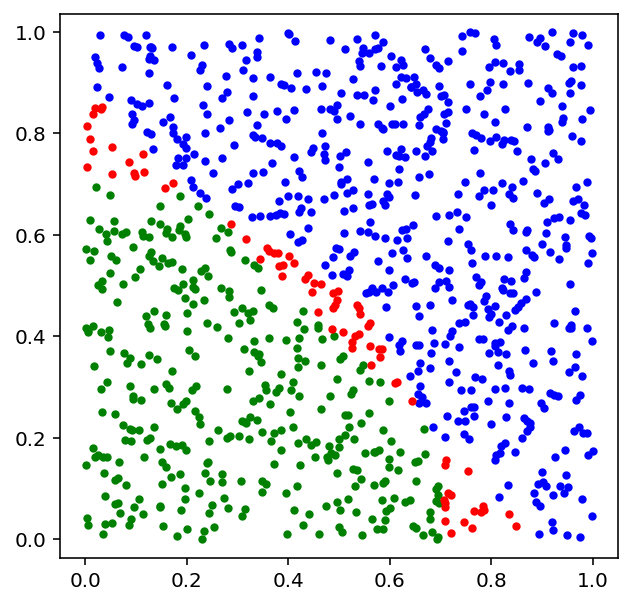

In [510]:
plot_data(datos,plabels=labels)